### Exploratory Data Analysis

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_excel('./Time-Series-Analysis-Resources/3-Regression/data/regression_data.xlsx')
print(df.head())

      x      y
0  1.42   1.70
1  1.86   7.80
2  1.48   2.05
3  3.14  12.30
4  2.21   9.35


### Quantitative Techniques
- Central Tendencies
- Measure of Spread

In [3]:
df.shape

(27, 2)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 27 entries, 0 to 26
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   x       27 non-null     float64
 1   y       27 non-null     float64
dtypes: float64(2)
memory usage: 564.0 bytes


In [5]:
print(df.mean())
print(df.median())
print(df.mode())

x    2.236667
y    6.070000
dtype: float64
x    2.18
y    3.20
dtype: float64
      x    y
0  1.85  1.7
1  2.18  2.4


In [7]:
# measure of spread
print(df.std())
print(df.var())

x    0.845468
y    4.930559
dtype: float64
x     0.714815
y    24.310415
dtype: float64


In [8]:
df.describe()

,x,y
count,27.000000,27.000000
mean,2.236667,6.070000
std,0.845468,4.930559
min,1.200000,1.200000
25%,1.730000,2.300000
50%,2.180000,3.200000
75%,2.520000,9.470000
max,4.600000,17.800000


### Graphical Method

In [ ]:
sns.histplot(data=df, x='x', stat='density', kde=True)

In [ ]:
sns.histplot(data=df, x='y', stat='density', kde=True)

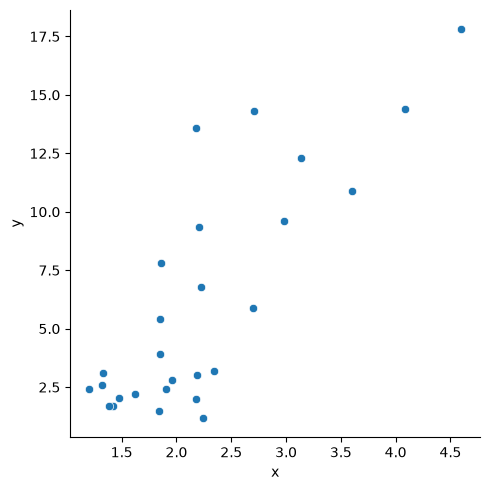

In [11]:
# relationship plot
sns.relplot(x='x', y='y', data=df)

<Axes: xlabel='x', ylabel='y'>

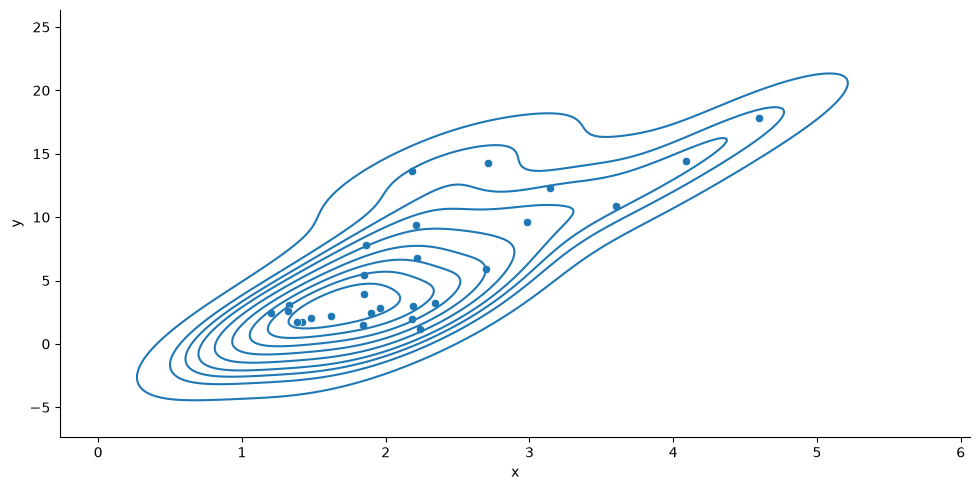

In [13]:
sns.relplot(x='x', y='y', data=df,aspect=2)
sns.kdeplot(data=df, x='x', y='y')

<Axes: >

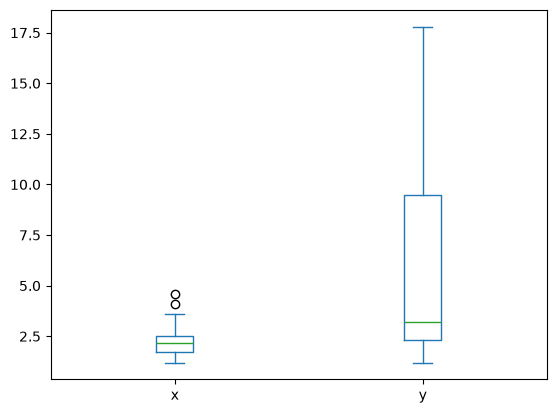

In [14]:
df.plot(kind='box')


# Least Square Regression

- This method of fitting a line is called **Least Square Regression**.

### Model Equation:

$$
\hat{y} = a + b * X
$$

where,

$$
b = \frac{\sum(x-\bar{x})(y-\bar{y})}{\sum(x-\bar{x})^2}
$$

$$
a = \bar{y} - b * \bar{x}
$$

### Scatter Plot

![Scatter Plot](least_square_regression_scatter_plot.png)


In [16]:
df.head()

,x,y
0,1.42,1.70
1,1.86,7.80
2,1.48,2.05
3,3.14,12.30
4,2.21,9.35


In [17]:
# slope of the line - b
# b = cov(x, y) / var(x)
cov = df.cov()
cov

,x,y
x,0.714815,3.390746
y,3.390746,24.310415


In [18]:
cov['x']['y'],cov['x']['x']

(np.float64(3.390746153846154), np.float64(0.7148153846153845))

In [19]:
b = cov['x']['y']/cov['x']['x']
print('Slope of the line =', b)

Slope of the line = 4.743527107590987


In [20]:
# intercept of the line 'a'
# a = mean(y) - b * mean(x)
mean_x = df['x'].mean()
mean_y = df['y'].mean()
a = mean_y - b * mean_x
print('Intercept of the line =', a)

Intercept of the line = -4.5396889639785085


In [21]:
def model_equation(x):
    y_hat = a + b*x
    return y_hat

In [23]:
model_equation(3)

np.float64(9.690892358794454)

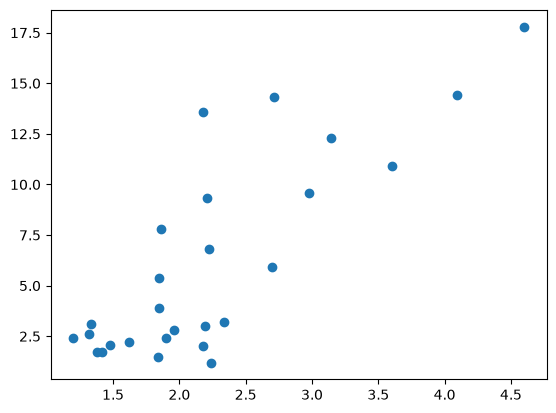

In [24]:
plt.scatter(df['x'],df['y'])

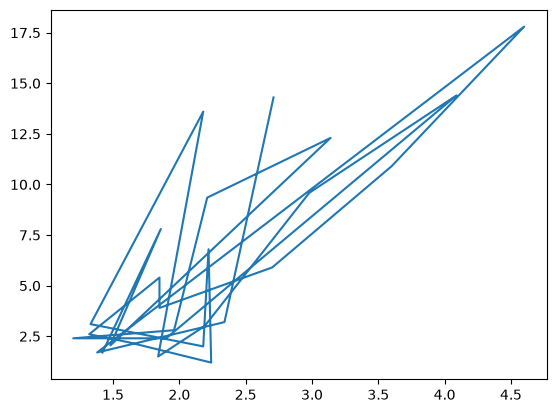

In [27]:
plt.plot(df['x'],df['y'])

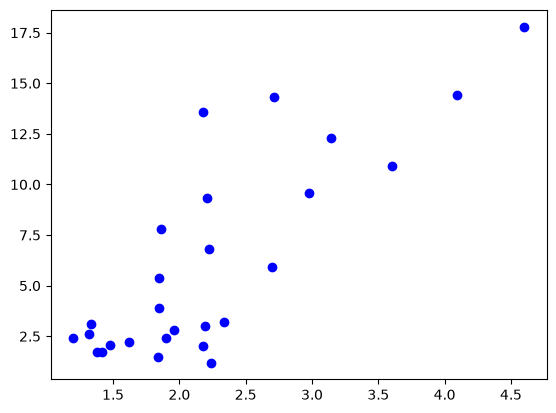

In [28]:
plt.plot(df['x'],df['y'],'bo')

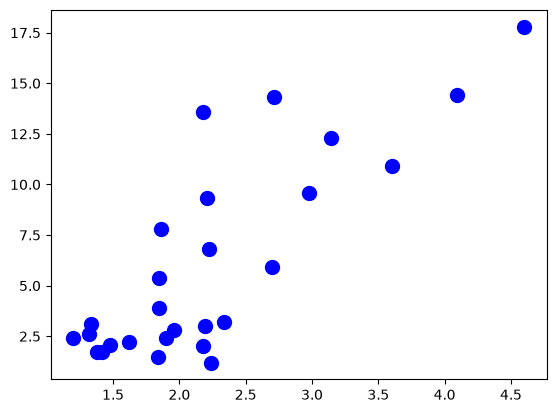

In [29]:
plt.plot(df['x'],df['y'],'bo',markersize=10)

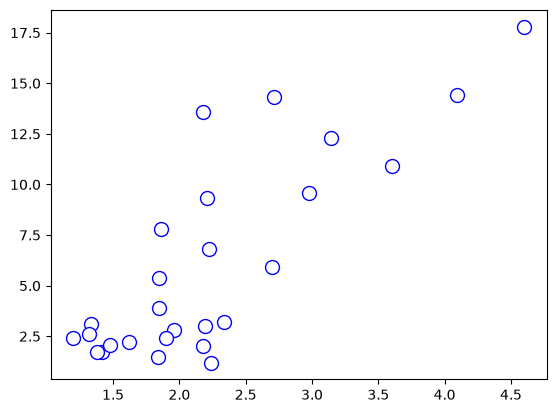

In [30]:
plt.plot(df['x'],df['y'],'bo',markersize=10,markerfacecolor='w')

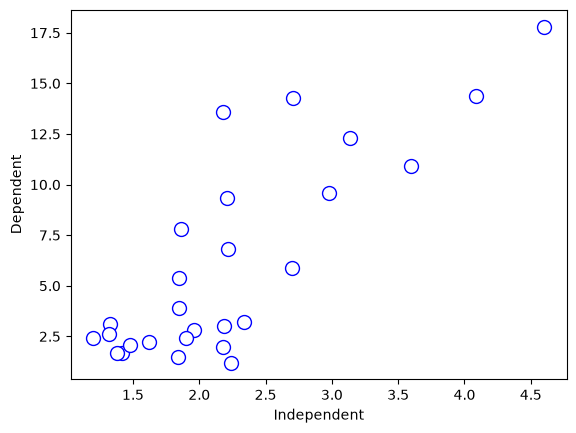

In [31]:
plt.plot(df['x'],df['y'],'bo',markersize=10,markerfacecolor='w')
plt.xlabel('Independent')
plt.ylabel('Dependent')
plt.show()

In [32]:
y_pred = model_equation(df['x'])

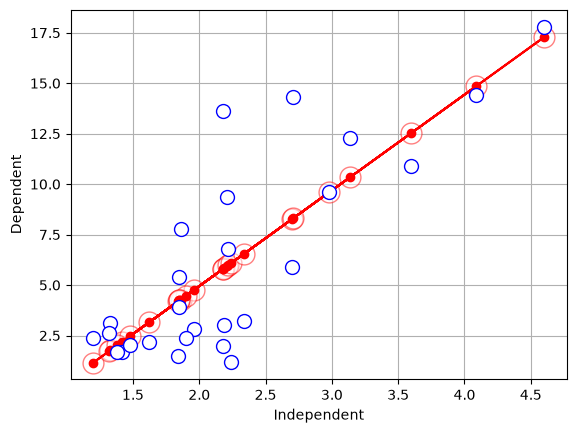

In [36]:
# linear regression line
plt.plot(df['x'],y_pred,'ro',markersize=15,markerfacecolor='w',alpha=0.5)
plt.plot(df['x'],y_pred,'r')
plt.plot(df['x'],y_pred,'ro')
plt.plot(df['x'],df['y'],'bo',markersize=10,markerfacecolor='w')
plt.xlabel('Independent')
plt.ylabel('Dependent')
plt.grid()
plt.show()

### Linear Regression with Sklearn

In [37]:
from sklearn.linear_model import LinearRegression

In [38]:
df.head()

,x,y
0,1.42,1.70
1,1.86,7.80
2,1.48,2.05
3,3.14,12.30
4,2.21,9.35


In [40]:
X = df.iloc[:,:-1].values # converting to an array
y = df.iloc[:,-1].values # converting to an array

X.shape, y.shape

((27, 1), (27,))

In [41]:
model = LinearRegression()
model.fit(X,y)
print("Model trained or fitted successfully!")

Model trained or fitted successfully!


In [42]:
# intercept and slope of the line
print(f"Intercept: {model.intercept_}")
print(f"Slope: {model.coef_[0]}")

Intercept: -4.539688963978516
Slope: 4.74352710759099


In [43]:
# prediction
y_pred_sk = model.predict(X)

In [45]:
test = np.array([3]).reshape(-1,1)
print(f"Predicted value for x = 3: {model.predict(test)}")

Predicted value for x = 3: [9.69089236]


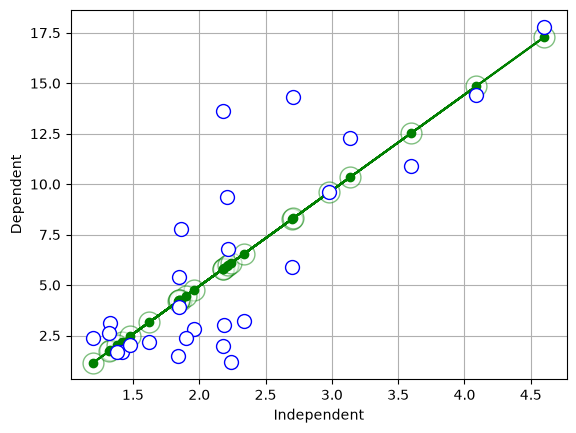

In [44]:
# linear regression line
plt.plot(df['x'],y_pred_sk,'go',markersize=15,markerfacecolor='w',alpha=0.5)
plt.plot(df['x'],y_pred_sk,'g')
plt.plot(df['x'],y_pred_sk,'go')
plt.plot(df['x'],df['y'],'bo',markersize=10,markerfacecolor='w')
plt.xlabel('Independent')
plt.ylabel('Dependent')
plt.grid()
plt.show()

### Linear Regression with Statsmodel

In [46]:
# OLS
import statsmodels.api as sm


In [47]:
df.head()

,x,y
0,1.42,1.70
1,1.86,7.80
2,1.48,2.05
3,3.14,12.30
4,2.21,9.35


In [48]:
model_sm = sm.OLS.from_formula(formula='y~x', data=df).fit()
print(model_sm.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.662
Model:                            OLS   Adj. R-squared:                  0.648
Method:                 Least Squares   F-statistic:                     48.88
Date:                Tue, 24 Nov 2026   Prob (F-statistic):           2.50e-07
Time:                        11:09:30   Log-Likelihood:                -66.251
No. Observations:                  27   AIC:                             136.5
Df Residuals:                      25   BIC:                             139.1
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -4.5397      1.619     -2.805      0.0

In [49]:
pd.DataFrame([[3]],columns=['x'])

,x
0,3


In [50]:
test_data = pd.DataFrame([[3]],columns=['x'])
model_sm.predict(test_data)

0    9.690892
dtype: float64

In [51]:
fittedvalues = model_sm.fittedvalues

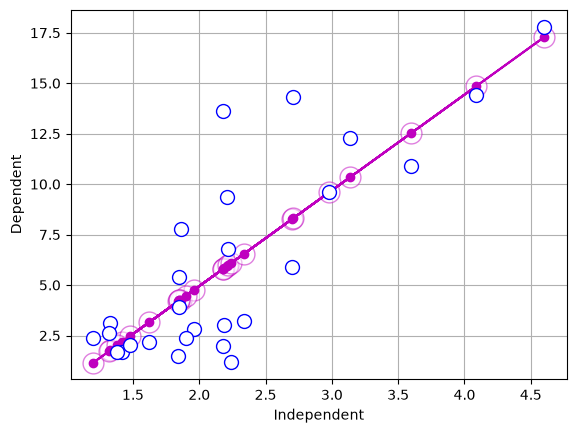

In [52]:
# linear regression line
plt.plot(df['x'],fittedvalues,'mo',markersize=15,markerfacecolor='w',alpha=0.5)
plt.plot(df['x'],fittedvalues,'m')
plt.plot(df['x'],fittedvalues,'mo')
plt.plot(df['x'],df['y'],'bo',markersize=10,markerfacecolor='w')
plt.xlabel('Independent')
plt.ylabel('Dependent')
plt.grid()
plt.show()

### Model Evaluation
- SST, SSR, SSE
- MSE
- $R^2$

In [53]:
df['y']

0      1.70
1      7.80
2      2.05
3     12.30
4      9.35
5      2.80
6      2.40
7      2.40
8     14.40
9      9.59
10     3.00
11     1.50
12    13.60
13     3.10
14     2.00
15     6.80
16     1.20
17     2.20
18     2.60
19     5.40
20     3.90
21     5.90
22    10.90
23    17.80
24     1.70
25     3.20
26    14.30
Name: y, dtype: float64

In [54]:
def sum_of_square(y_value):
    mean_y = y_value.mean()
    ss = np.sum(np.square(y_value - mean_y))
    return ss


In [55]:
SST = sum_of_square(df['y'])
SST

np.float64(632.0708000000001)

In [56]:
SSR = sum_of_square(fittedvalues)
SSR

np.float64(418.1865036889566)

In [57]:
SSE = SST - SSR
SSE

np.float64(213.8842963110435)

In [59]:
error = np.sum(np.square(df['y'] - fittedvalues))
error

np.float64(213.88429631104322)

In [60]:
# MSE(Mean Squared Error)
n = len(df)
k = 1 # number of independent variables
MSE = error / (n-k)
MSE

np.float64(8.226319088886278)

In [61]:
# R-Squared (Explained variance)

R_squared = SSR / SST
R_squared

np.float64(0.6616133883877511)